## Bank Loan Approval Prediction 

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split


df=pd.read_csv("train_u6lujuX_CVtuZ9i (1).csv")


df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [4]:

df['LoanAmount'].fillna(df['LoanAmount'].mean(), )

df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].mean(), )

df['Credit_History'].fillna(df['Credit_History'].mean(), )

df.dropna(inplace=True)

print(df.isnull().sum())
df['LoanAmount'] = df['LoanAmount'].round(1)
df['Credit_History'] = df['Credit_History'].round(1)
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].round(1)





Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [5]:
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N
10,LP001024,Male,Yes,2,Graduate,No,3200,700.0,70.0,360.0,1.0,Urban,Y


In [6]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

df = df.drop(columns=["Loan_ID"], errors="ignore")

df['Dependents'] = df['Dependents'].replace('3+', 3).astype(float)


le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])

df['Married'] = le.fit_transform(df['Married'])

df['Education'] = le.fit_transform(df['Education'])

df['Self_Employed'] = le.fit_transform(df['Self_Employed'])

df['Loan_Status'] = le.fit_transform(df['Loan_Status'])

df['Property_Area'] = le.fit_transform(df['Property_Area'])

In [7]:
df.to_csv('Cleaned_bank-loan-data.csv', index=False)
print("Project Complete! 'Cleaned_bank-loan-data.csv' has been generated in your workspace.")
df.head(10)

Project Complete! 'Cleaned_bank-loan-data.csv' has been generated in your workspace.


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,1,1,1.0,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,1,1,0.0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,1,1,0.0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,1,0,0.0,0,0,6000,0.0,141.0,360.0,1.0,2,1
5,1,1,2.0,0,1,5417,4196.0,267.0,360.0,1.0,2,1
6,1,1,0.0,1,0,2333,1516.0,95.0,360.0,1.0,2,1
7,1,1,3.0,0,0,3036,2504.0,158.0,360.0,0.0,1,0
8,1,1,2.0,0,0,4006,1526.0,168.0,360.0,1.0,2,1
9,1,1,1.0,0,0,12841,10968.0,349.0,360.0,1.0,1,0
10,1,1,2.0,0,0,3200,700.0,70.0,360.0,1.0,2,1


--- CONFUSION MATRIX ---
[[13 15]
 [ 2 66]]

--- PERFORMANCE METRICS ---
              precision    recall  f1-score   support

           0       0.87      0.46      0.60        28
           1       0.81      0.97      0.89        68

    accuracy                           0.82        96
   macro avg       0.84      0.72      0.75        96
weighted avg       0.83      0.82      0.80        96



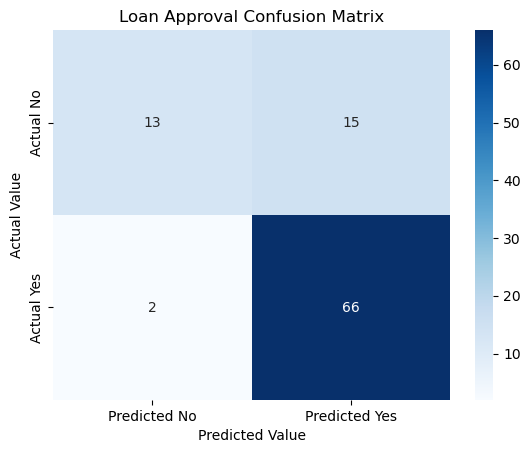


--- SINGLE PREDICTION ---
Result: Loan Approved!


In [8]:

df=pd.read_csv("Cleaned_bank-loan-data.csv")

X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



model = RandomForestClassifier(random_state=42)


model.fit(X_train, y_train)


y_pred = model.predict(X_test)


matrix = confusion_matrix(y_test, y_pred)
print("--- CONFUSION MATRIX ---")
print(matrix)


print("\n--- PERFORMANCE METRICS ---")
print(classification_report(y_test, y_pred))


sns.heatmap(
    matrix,
    annot=True,
    cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"],
)
plt.title("Loan Approval Confusion Matrix")
plt.xlabel("Predicted Value")
plt.ylabel("Actual Value")
plt.show()

new_applicant_data = {
    'Gender':1,               # 1 = Male
    'Married':1,              # 1 = Yes
    'Dependents': [0.0],         # 0 dependents
    'Education':1,            # 1 = Graduate
    'Self_Employed':1,        # 0 = No
    'ApplicantIncome':50000,   # Income
    'CoapplicantIncome': [0.0],  # No co-applicant income
    'LoanAmount': [146.4],       # Loan request size
    'Loan_Amount_Term': [360.0], # 30-year term
    'Credit_History': [1.0],     # Clear historical background record
    'Property_Area': [2]         # 2 = Urba
}

new_applicant = pd.DataFrame(new_applicant_data)

# Predict safely
prediction = model.predict(new_applicant)

print("\n--- SINGLE PREDICTION ---")
if prediction[0] == 1:
    print("Result: Loan Approved!")
else:
    print("Result: Loan Denied.")


Original training target distribution:
Loan_Status
1    264
0    120
Name: count, dtype: int64

Resampled training target distribution:
Loan_Status
0    264
1    264
Name: count, dtype: int64
------------------------------

--- PERFORMANCE METRICS (WITH SMOTE) ---
                 Model  Accuracy  F1 Score
0        Random Forest  0.812500  0.876712
1    Gradient Boosting  0.770833  0.847222
2  Logistic Regression  0.739583  0.820144
3        Decision Tree  0.718750  0.805755


/home/ayush/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/tmp/ipykernel_10140/3713952401.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Model", y="Accuracy", data=results_df, palette="viridis")


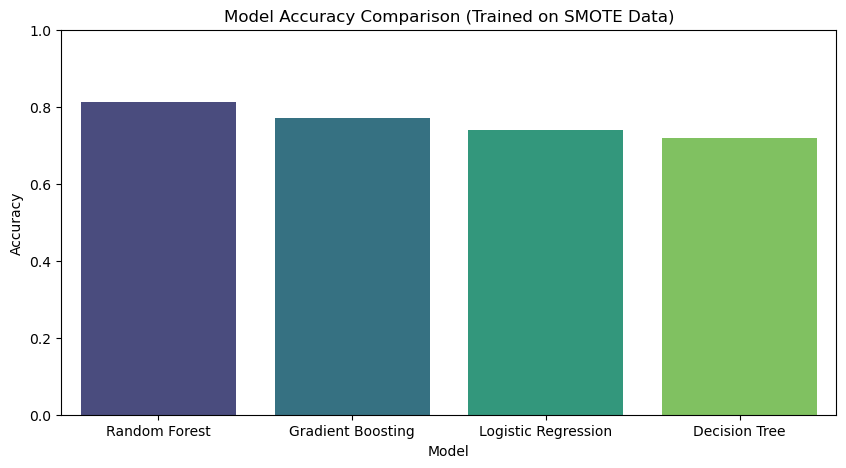

In [10]:
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Initialize and apply SMOTE to the training data only
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Original training target distribution:")
print(y_train.value_counts())
print("\nResampled training target distribution:")
print(y_train_smote.value_counts())
print("-" * 30)

# 2. Initialize the models
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# 3. Train and evaluate
results = []

for name, model in models.items():
    # Train using the balanced SMOTE data
    model.fit(X_train_smote, y_train_smote)
    
    # Predict using the untouched original test data
    y_pred = model.predict(X_test)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred) 
    
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "F1 Score": f1
    })

# 4. Display results
results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
print("\n--- PERFORMANCE METRICS (WITH SMOTE) ---")
print(results_df)

# Plotting the comparison
plt.figure(figsize=(10, 5))
sns.barplot(x="Model", y="Accuracy", data=results_df, palette="viridis")
plt.title("Model Accuracy Comparison (Trained on SMOTE Data)")
plt.ylim(0, 1)
plt.show()

In [11]:
import joblib
from sklearn.ensemble import RandomForestClassifier

# 1. Train your final model (using the SMOTE data from the previous step)
final_rf = RandomForestClassifier(random_state=42)
final_rf.fit(X_train_smote, y_train_smote)

# 2. Define the filename
model_filename = 'final_rf_loan_model.pkl'

# 3. Save the model to disk
joblib.dump(final_rf, model_filename)
print(f"Success! Model saved as {model_filename}")

# --- Later on, when you need to use the model in production ---

# Load the model from disk
loaded_model = joblib.load(model_filename)

# You can now use loaded_model to make predictions on new data
# prediction = loaded_model.predict(new_applicant_data)

Success! Model saved as final_rf_loan_model.pkl


In [12]:
import streamlit as st
import pandas as pd
import joblib
import time

# --- 1. PAGE CONFIGURATION ---
st.set_page_config(
    page_title="Loan Approval Predictor",
    page_icon="🏦",
    layout="centered",
    initial_sidebar_state="expanded",
)

# Custom CSS for styling
st.markdown("""
    <style>
    .main {
        background-color: #f8f9fa;
    }
    .stButton>button {
        background-color: #4CAF50;
        color: white;
        border-radius: 5px;
        padding: 10px 24px;
        font-weight: bold;
        width: 100%;
    }
    .stButton>button:hover {
        background-color: #45a049;
    }
    h1 {
        color: #1E3A8A;
        text-align: center;
    }
    </style>
""", unsafe_allow_html=True)

# --- 2. LOAD THE MODEL ---
@st.cache_resource
def load_model():
    # Load the model saved via joblib
    try:
        return joblib.load('final_rf_loan_model.pkl')
    except FileNotFoundError:
        st.error("Model file not found. Please ensure 'final_rf_loan_model.pkl' is in the directory.")
        return None

model = load_model()

# --- 3. HEADER & INTRODUCTION ---
st.title("🏦 Smart Loan Approval System")
st.markdown("---")
st.write("Fill in the applicant's details below to instantly predict if their loan will be approved based on our Machine Learning model.")

# --- 4. USER INPUT FORM ---
# Creating columns for a cleaner layout
col1, col2 = st.columns(2)

with col1:
    st.subheader("Personal Details")
    gender = st.selectbox("Gender", ["Male", "Female"])
    married = st.selectbox("Marital Status", ["Yes", "No"])
    dependents = st.selectbox("Dependents", ["0", "1", "2", "3+"])
    education = st.selectbox("Education", ["Graduate", "Not Graduate"])

with col2:
    st.subheader("Financial Details")
    self_employed = st.selectbox("Self Employed", ["Yes", "No"])
    property_area = st.selectbox("Property Area", ["Urban", "Semiurban", "Rural"])
    credit_history = st.selectbox("Credit History Meets Guidelines?", ["Yes", "No"])

st.markdown("---")
st.subheader("Income & Loan Details")

col3, col4, col5 = st.columns(3)
with col3:
    applicant_income = st.number_input("Applicant Income ($)", min_value=0, value=5000, step=500)
with col4:
    coapplicant_income = st.number_input("Coapplicant Income ($)", min_value=0, value=0, step=500)
with col5:
    loan_amount = st.number_input("Loan Amount Requested (in Thousands)", min_value=1.0, value=150.0, step=10.0)

loan_amount_term = st.slider("Loan Term (in Days)", min_value=12.0, max_value=480.0, value=360.0, step=12.0)

# --- 5. PREDICTION LOGIC ---
if st.button("Predict Loan Status"):
    if model is not None:
        with st.spinner('Analyzing applicant profile...'):
            time.sleep(1) # Simulating a slight processing delay for UX
            
            # Convert user inputs to the numeric format the model expects
            # (Matches the LabelEncoder mapping from your original code)
            
            # Gender: Male=1, Female=0
            gender_val = 1 if gender == "Male" else 0
            
            # Married: Yes=1, No=0
            married_val = 1 if married == "Yes" else 0
            
            # Dependents: "3+" -> 3.0
            dep_val = 3.0 if dependents == "3+" else float(dependents)
            
            # Education: Graduate=0, Not Graduate=1 (Based on standard LabelEncoder alphabetical sorting)
            edu_val = 0 if education == "Graduate" else 1
            
            # Self Employed: Yes=1, No=0 (assuming missing values were handled)
            self_emp_val = 1 if self_employed == "Yes" else 0
            
            # Credit History: Yes=1.0, No=0.0
            credit_val = 1.0 if credit_history == "Yes" else 0.0
            
            # Property Area: Rural=0, Semiurban=1, Urban=2
            prop_mapping = {"Rural": 0, "Semiurban": 1, "Urban": 2}
            prop_val = prop_mapping[property_area]

            # Create a DataFrame for prediction (must match training feature order exactly)
            input_data = pd.DataFrame({
                'Gender': [gender_val],
                'Married': [married_val],
                'Dependents': [dep_val],
                'Education': [edu_val],
                'Self_Employed': [self_emp_val],
                'ApplicantIncome': [applicant_income],
                'CoapplicantIncome': [coapplicant_income],
                'LoanAmount': [loan_amount],
                'Loan_Amount_Term': [loan_amount_term],
                'Credit_History': [credit_val],
                'Property_Area': [prop_val]
            })

            # Make the prediction
            prediction = model.predict(input_data)
            
            # Display results
            st.markdown("---")
            if prediction[0] == 1:
                st.success("🎉 **LOAN APPROVED**")
                st.balloons()
                st.write("Based on the provided profile, this applicant is considered low risk.")
            else:
                st.error("🛑 **LOAN DENIED**")
                st.write("Based on the provided profile, this applicant does not meet the approval criteria.")

# Sidebar Information
st.sidebar.title("About")
st.sidebar.info(
    "This application uses a Random Forest Machine Learning model "
    "to predict whether a bank loan should be approved or denied based on "
    "historical demographic and financial data."
)
st.sidebar.text("Model accuracy: ~82%")

2026-09-11 12:41:27.987 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 12:41:27.988 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 12:41:28.035 
  command:

    streamlit run /home/ayush/anaconda3/lib/python3.13/site-packages/ipykernel_launcher.py [ARGUMENTS]
2026-09-11 12:41:28.035 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 12:41:28.036 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 12:41:28.037 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-11 12:41:28.037 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored w

DeltaGenerator(_root_container=1, _parent=DeltaGenerator())

## Practice Questions: